In [1]:
import pandas as pd

In [12]:
df = pd.read_csv("train.csv")

In [13]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [14]:
#check the shape
df.shape

(891, 12)

In [15]:
#check the columns names
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [18]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [19]:
#check missing values
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [20]:
#find the percentage of missing values
(df.isnull().sum() / len(df)) * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

In [22]:
#missing-value table
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})
missing

,Missing Values,Percentage
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
Age,177,19.865320
SibSp,0,0.000000
Parch,0,0.000000
Ticket,0,0.000000
Fare,0,0.000000


In [23]:
#Check numerical columns
df.select_dtypes(include="number").columns

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

In [24]:
#Check categorical/text columns 
df.select_dtypes(include="object").columns

Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')

In [25]:
df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [26]:
#How many passengers in each class
df["Pclass"].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [27]:
#How many passengers embarked from each port.
df["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [28]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [29]:
import matplotlib.pyplot as plt

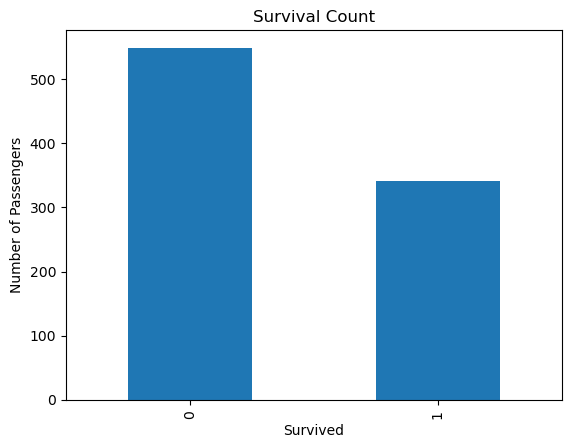

In [30]:
#first bar chart
df["Survived"].value_counts().plot(kind="bar")

plt.title("Survival Count")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")

plt.show()

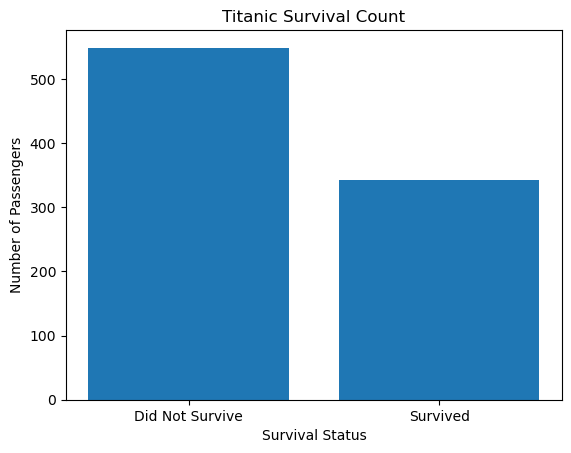

In [31]:
survival_counts = df["Survived"].value_counts()

plt.bar(["Did Not Survive", "Survived"], survival_counts)

plt.title("Titanic Survival Count")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")

plt.show()

Survived By Gender

In [32]:
df.groupby("Sex")["Survived"].value_counts()

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64

In [33]:
survival_by_sex = pd.crosstab(df["Sex"], df["Survived"])
survival_by_sex

Survived,0,1
Sex,,
female,81,233
male,468,109


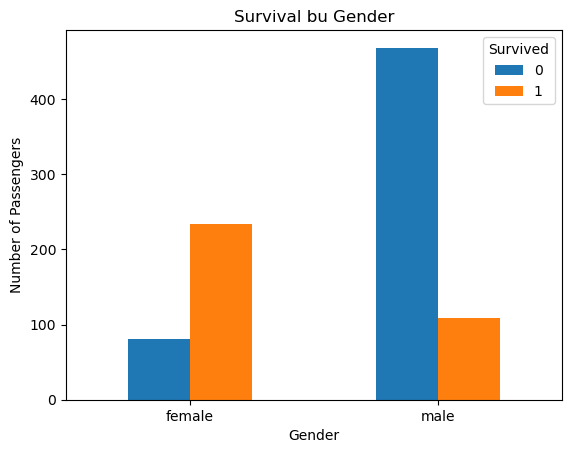

In [34]:
survival_by_sex.plot(kind="bar")

plt.title("Survival bu Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.xticks(rotation=0)

plt.show()

In [35]:
survival_rate = df.groupby("Sex")["Survived"].mean() * 100
survival_rate

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

Survived By Passenger Class

In [36]:
df.groupby("Pclass")["Survived"].value_counts()

Pclass  Survived
1       1           136
        0            80
2       0            97
        1            87
3       0           372
        1           119
Name: count, dtype: int64

In [37]:
survival_by_class = pd.crosstab(df["Pclass"], df["Survived"])
survival_by_class

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


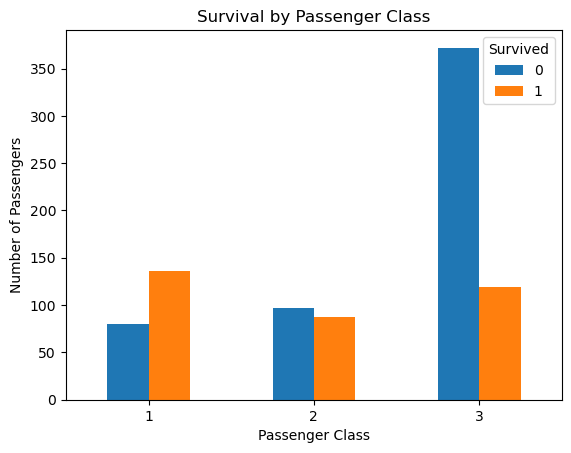

In [38]:
survival_by_class.plot(kind="bar")

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)

plt.show()

In [39]:
survival_rate_class = df.groupby("Pclass")["Survived"].mean() * 100
survival_rate_class

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

Analyze Age

In [40]:
#what does the age distribution of titanic passengers look like

In [41]:
df["Age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [42]:
import seaborn as sns

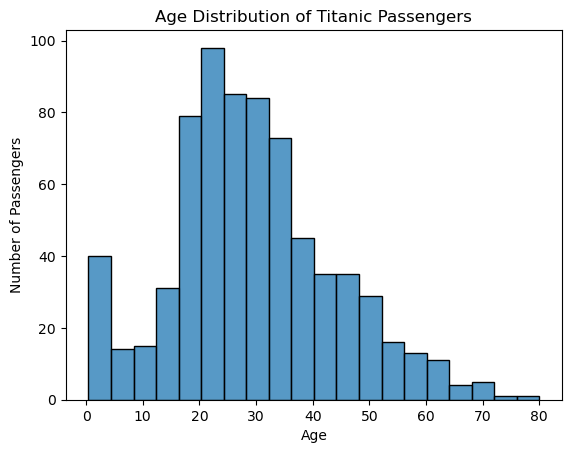

In [43]:
sns.histplot(data=df, x="Age", bins=20)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

In [46]:
df["Age"].isnull().sum()

np.int64(177)

Age vs Survival

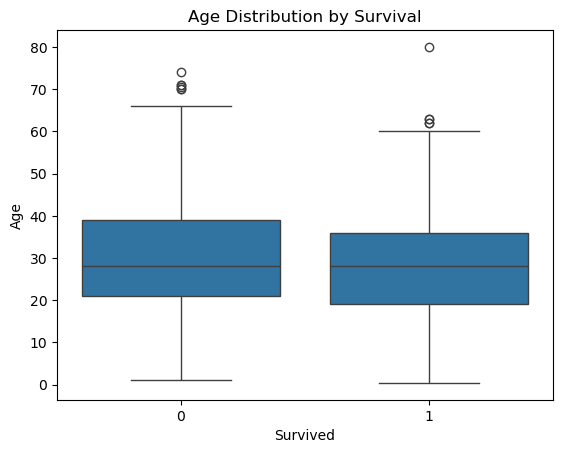

In [47]:
sns.boxplot(data=df, x="Survived", y="Age")

plt.title("Age Distribution by Survival")
plt.xlabel("Survived")
plt.ylabel("Age")

plt.show()

Survival Rate by Age Group

In [48]:
#Create age groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0,12,18,30,50,80],
    labels=["Child","Teen","Young Adult","Adult","Senior"]
)

In [50]:
df["AgeGroup"].value_counts()

AgeGroup
Young Adult    270
Adult          241
Teen            70
Child           69
Senior          64
Name: count, dtype: int64

In [51]:
#Calculate survival rate for each age group
age_survival = df.groupby("AgeGroup", observed=True)["Survived"].mean() * 100
age_survival

AgeGroup
Child          57.971014
Teen           42.857143
Young Adult    35.555556
Adult          42.323651
Senior         34.375000
Name: Survived, dtype: float64

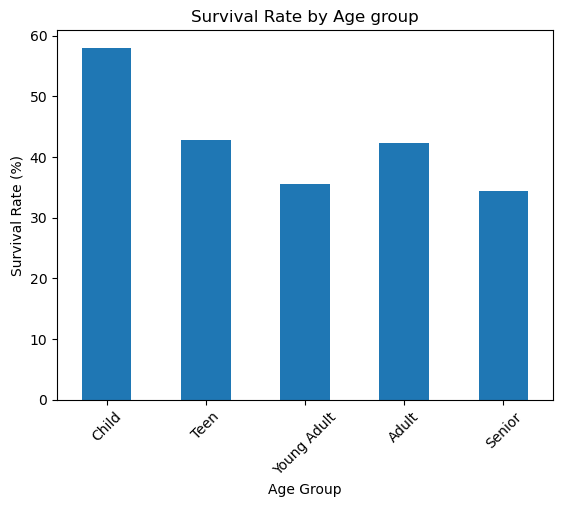

In [54]:
age_survival.plot(kind="bar")

plt.title("Survival Rate by Age group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=45)

plt.show()

Analyze Tickets Fare

In [55]:
df["Fare"].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

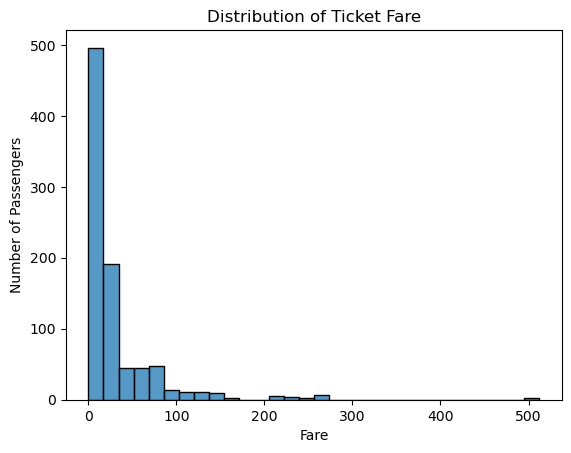

In [56]:
sns.histplot(data=df, x="Fare", bins=30)

plt.title("Distribution of Ticket Fare")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")

plt.show()

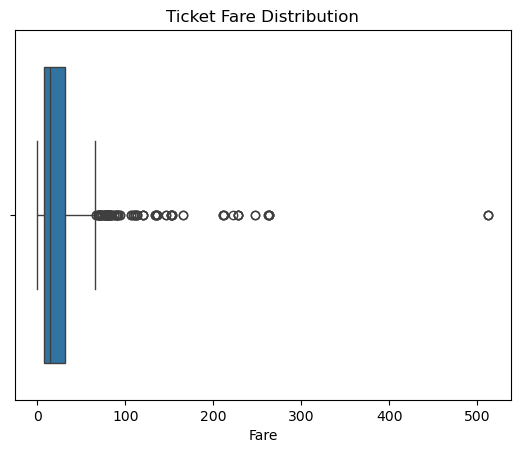

In [57]:
sns.boxplot(data=df, x="Fare")

plt.title("Ticket Fare Distribution")
plt.xlabel("Fare")

plt.show()

Create a Family Size Feature

In [60]:
#Creating a new column from existing columns
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

In [61]:
df[["SibSp", "Parch", "FamilySize"]].head(10)

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1
5,0,0,1
6,0,0,1
7,3,1,5
8,0,2,3
9,1,0,2


In [62]:
df["FamilySize"].value_counts().sort_index()

FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

Calculate survival rate for each family size

In [63]:
family_survival = df.groupby("FamilySize")["Survived"].mean() * 100
family_survival

FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64

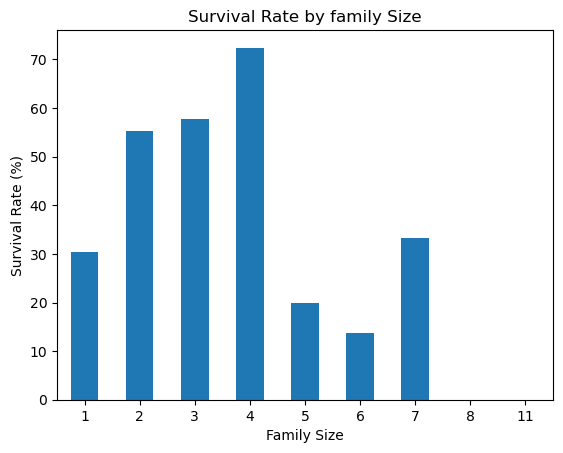

In [64]:
family_survival.plot(kind="bar")

plt.title("Survival Rate by family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)

plt.show()

Multivariable Analysis

In [65]:
survival_gender_class = df.groupby(
    ["Sex", "Pclass"]
)["Survived"].mean() * 100

survival_gender_class

Sex     Pclass
female  1         96.808511
        2         92.105263
        3         50.000000
male    1         36.885246
        2         15.740741
        3         13.544669
Name: Survived, dtype: float64

In [67]:
survival_gender_class_table = pd.crosstab(
    df["Sex"],
    df["Pclass"],
    values=df["Survived"],
    aggfunc="mean"
) * 100

survival_gender_class_table

Pclass,1,2,3
Sex,,,
female,96.808511,92.105263,50.000000
male,36.885246,15.740741,13.544669


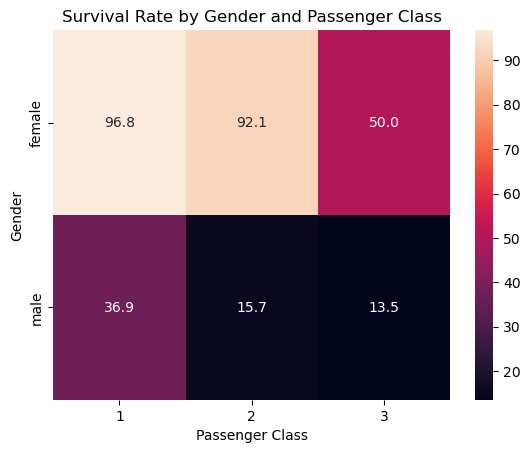

In [68]:
sns.heatmap(
    survival_gender_class_table,
    annot=True,
    fmt=".1f"
)

plt.title("Survival Rate by Gender and Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Gender")

plt.show()

Correction Analysis

correlation = df[
    ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize"]].corr()
correlation

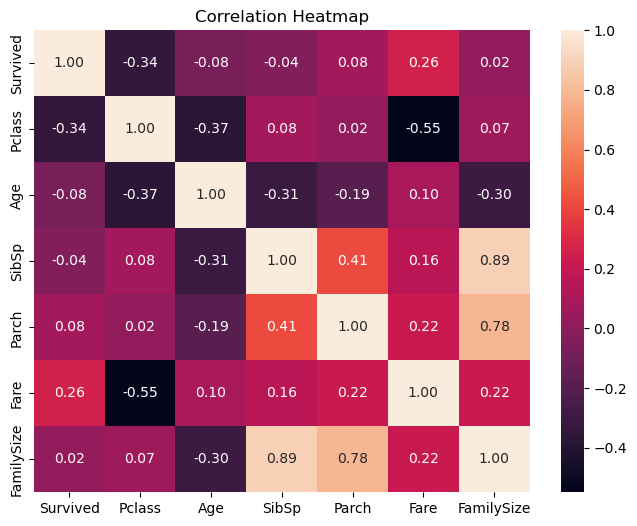

In [70]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

# Titanic Dataset — Exploratory Data Analysis

## 1. Dataset Overview

The Titanic dataset contains 891 passengers and 12 columns.

## 2. Missing Values

- Age has 177 missing values.
- Cabin has 687 missing values.
- Embarked has 2 missing values.

## 3. Overall Survival

- 342 passengers survived.
- 549 passengers did not survive.

## 4. Survival by Gender

- Female survival rate: 74.20%
- Male survival rate: 18.89%

## 5. Survival by Passenger Class

- 1st class: 62.96%
- 2nd class: 47.28%
- 3rd class: 24.24%

## 6. Age Analysis

Most passengers with recorded ages were approximately between 20 and 35 years old.

## 7. Age Group Analysis

- Child: 57.97%
- Teen: 42.86%
- Young Adult: 35.56%
- Adult: 42.32%
- Senior: 34.38%

## 8. Fare Analysis

The fare distribution is strongly right-skewed. Most passengers paid relatively low fares, while a smaller number paid very high fares.

The mean fare was 32.20, while the median was 14.45.

## 9. Family Size

Most passengers were traveling alone.

FamilySize = 1 had 537 passengers.

## 10. Family Size and Survival

Family sizes of 2–4 showed higher survival rates in this dataset, while some larger family groups had lower rates.

Small groups should be interpreted carefully because they contain fewer observations.

## 11. Gender and Passenger Class

Survival rates varied substantially across combinations of gender and passenger class.

## 12. Correlation

The strongest relationships observed included:

- Pclass and Fare: -0.55
- SibSp and FamilySize: 0.89
- Parch and FamilySize: 0.78

Survived had a correlation of approximately -0.34 with Pclass and 0.26 with Fare.